In [31]:
import math
import numpy as np
import random
from graphviz import Digraph

In [32]:
class Value:
    def __init__(self,data,child=(),label='',op=''):
        self.data=data
        self.prev=set(child)
        self.label=label
        self.op=op
        self.grad=0.0
        self._backward=lambda: None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data+other.data,(self,other),op='+')

        def backward():
            self.grad+=out.grad
            other.grad+=out.grad
            
        out._backward=backward

        return out
    
    def __radd__(self, other): # fallback when the passed args wont match the expected in add function
        return self+other
    
    def __neg__(self):
        return self*-1
    
    def __sub__(self, other):
        return self+(-other)
    
    def __mul__(self, other):
        other=other if isinstance(other,Value) else Value(other)
        out=Value(self.data*other.data,(self,other),op='*')

        def backward():
            self.grad+=other.data*out.grad
            other.grad+=self.data*out.grad     

        out._backward=backward

        return out

    def __rmul__(self, other):
        return self*other

    def __pow__(self, other):
        assert isinstance(other, (int, float))
        out=Value(self.data**other,(self,),op='pow')
    
        def backward():
            self.grad+=out.grad*(other*(self.data**(other-1)))
    
        out._backward=backward
        
        return out
    
    def __truediv__(self, other):
        return self*(other**-1)

    def exp(self):
        x=math.exp(self.data)
        out=Value(x,(self,),op='exp')

        def backward():
            self.grad+=out.grad*out.data

        out._backward=backward

        return out

    def tanh(self):
        t=math.tanh(self.data)
    
        out=Value(t,(self,),op='tanh')
    
        def backward():
            self.grad+=(1-t**2)*out.grad
    
        out._backward=backward
    
        return out
    
    def backprop(self):
        topo=[]
        visited=set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                        
                for child in v.prev:
                    build_topo(child)
            
                topo.append(v)

        build_topo(self)

        self.grad=1
        for node in reversed(topo):
            node._backward()

In [33]:
class Neuron:
    def __init__(self,nin):
        self.w=[Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b=Value(random.uniform(-1,1))

    def __call__(self,x):
        s=sum(wi*xi for wi,xi in zip(self.w,x))+self.b
        out=s.tanh()
        return out


class Layer:
    def __init__(self,nin,nout):
        self.neurons=[Neuron(nin) for _ in range(nout)]

    def __call__(self,x):
        out=[n(x) for n in self.neurons]
        return out


class MLP:
    def __init__(self,nin,nouts):
        sz=[nin]+nouts
        self.layers=[Layer(sz[i],sz[i+1]) for i in range(len(nouts))]

    def __call__(self,x):
        for layer in self.layers:
            x=layer(x)

        return x


mlp=MLP(3,[3,4,4,5,3])
mlp_out=mlp([1,2,3])


In [34]:
x1=Value(4.0,label='x1')
x2=Value(5.0,label='x2')

w1=Value(1.0,label='w1')
w2=Value(2.0,label='w2')

w1x1=w1*x1
w1x1.label='w1x1'

w2x2=w2*x2
w2x2.label='w2x2'

b=Value(2,label='b')

t=w1x1+w2x2
t.label='t'

s=t+b
s.label='s'

e=(2*s).exp()
e.label='e'

o=(e-1)/(e+1)
o.label='o'


In [35]:
print(x1*1,1*x1)

Value(data=4.0) Value(data=4.0)


In [36]:
print(f"w1.grad > {w1.grad}")
print(f"w2.grad > {w2.grad}")
print(f"x1.grad > {x1.grad}")
print(f"x2.grad > {x2.grad}")
print(f"w1x1.grad > {w1x1.grad}")
print(f"w2x2.grad > {w2x2.grad}")
print(f"t.grad > {t.grad}")
print(f"b.grad > {b.grad}")
print(f"s.grad > {s.grad}")
print(f"o.grad > {o.grad}")

o.backprop()
print("\n")

print(f"w1.grad > {w1.grad}")
print(f"w2.grad > {w2.grad}")
print(f"x1.grad > {x1.grad}")
print(f"x2.grad > {x2.grad}")
print(f"w1x1.grad > {w1x1.grad}")
print(f"w2x2.grad > {w2x2.grad}")
print(f"t.grad > {t.grad}")
print(f"b.grad > {b.grad}")
print(f"s.grad > {s.grad}")
print(f"o.grad > {o.grad}")

w1.grad > 0.0
w2.grad > 0.0
x1.grad > 0.0
x2.grad > 0.0
w1x1.grad > 0.0
w2x2.grad > 0.0
t.grad > 0.0
b.grad > 0.0
s.grad > 0.0
o.grad > 0.0


w1.grad > 2.0232049322358337e-13
w2.grad > 2.529006165294792e-13
x1.grad > 5.058012330589584e-14
x2.grad > 1.0116024661179169e-13
w1x1.grad > 5.058012330589584e-14
w2x2.grad > 5.058012330589584e-14
t.grad > 5.058012330589584e-14
b.grad > 5.058012330589584e-14
s.grad > 5.058012330589584e-14
o.grad > 1


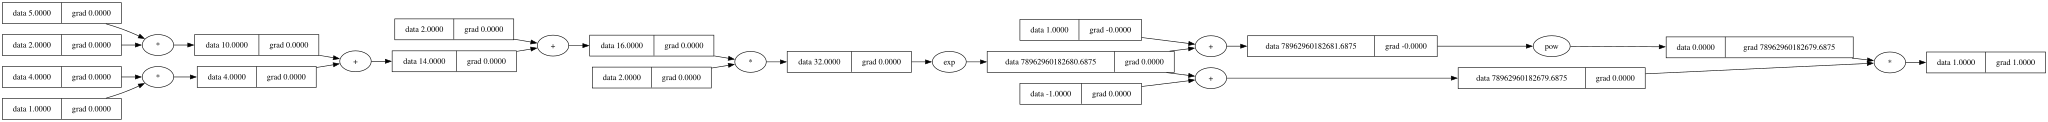

In [42]:
def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v.prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root, format='svg', rankdir='LR'):
    """
    format: png | svg | ...
    rankdir: TB (top to bottom graph) | LR (left to right)
    """
    assert rankdir in ['LR', 'TB']
    nodes, edges = trace(root)
    dot = Digraph(format=format, graph_attr={'rankdir': rankdir}) #, node_attr={'rankdir': 'TB'})
    
    for n in nodes:
        dot.node(name=str(id(n)), label = "{ data %.4f | grad %.4f }" % (n.data, n.grad), shape='record')
        if n.op:
            dot.node(name=str(id(n)) + n.op, label=n.op)
            dot.edge(str(id(n)) + n.op, str(id(n)))
    
    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2.op)
    
    return dot


draw_dot(o)